# 01 · Exploratory analysis of life expectancy

**Question for this project:** How has life expectancy changed across the world since 2000, who is being left behind, and what can we reasonably say about the years ahead?

This notebook is the first step: understand the data before modelling it. It covers

1. Data coverage and quality
2. Regional trends (population-weighted)
3. The gap between women and men
4. A closer look at one country and one region
5. The COVID-19 shock
6. Healthy life expectancy (HALE) versus total life expectancy
7. How life expectancy relates to income and other factors

**Data:** WHO Global Health Observatory (life expectancy and HALE at birth, by sex) and the World Bank World Development Indicators. Build the dataset first by running, from the project root:

```bash
python -m src.fetch_data
python -m src.build_dataset
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from src.config import PANEL_PATH, FIGURES_DIR
from src.plotting import set_style, REGION_COLORS, SEX_COLORS, SEQUENTIAL, PALETTE, INK_SECONDARY, SURFACE

set_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)

if not PANEL_PATH.exists():
    raise FileNotFoundError("No dataset yet. Run `python -m src.fetch_data` then `python -m src.build_dataset` from the project root.")

panel = pd.read_csv(PANEL_PATH)

# Change these to explore a different country (ISO3 code) or WHO region.
FOCUS_COUNTRY = "KEN"
FOCUS_REGION = "Africa"

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png")

## 1. Data overview and quality

In [2]:
both = panel[panel["sex"] == "both"].copy()
LATEST = int(both.loc[both["life_expectancy"].notna(), "year"].max())
FIRST = int(both.loc[both["life_expectancy"].notna(), "year"].min())

if FOCUS_COUNTRY not in set(panel["iso3"]):
    FOCUS_COUNTRY = both["iso3"].iloc[0]
    print(f"Focus country not in data; using {FOCUS_COUNTRY} instead.")

print(f"{panel['iso3'].nunique()} countries, life expectancy available {FIRST}-{LATEST}")
print(f"{len(panel):,} rows (country x year x sex), {panel.shape[1]} columns")
both.head()

185 countries, life expectancy available 2000-2023
13,320 rows (country x year x sex), 42 columns


,iso3,country,who_region_code,who_region,wb_region,income_group,year,sex,life_expectancy,life_expectancy_low,...,hiv_incidence,tb_incidence,malaria_incidence,road_traffic_deaths,suicide_rate,deaths_communicable_pct,deaths_ncd_pct,deaths_injury_pct,log_gdp_pc_ppp,le_sex_gap
0,AFG,Afghanistan,EMR,Eastern Mediterranean,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2000,both,54.2,51.2,...,0.1,148.0,84.48,14.7,4.36,60.962448,29.517021,9.520531,7.388839,0.9
1,AFG,Afghanistan,EMR,Eastern Mediterranean,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2001,both,54.3,51.3,...,0.1,175.0,83.83,15.1,4.38,NaN,NaN,NaN,7.282150,1.0
2,AFG,Afghanistan,EMR,Eastern Mediterranean,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2002,both,55.5,52.5,...,0.1,197.0,83.79,14.9,4.26,NaN,NaN,NaN,7.481166,0.3
3,AFG,Afghanistan,EMR,Eastern Mediterranean,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2003,both,56.3,53.4,...,0.1,215.0,70.81,15.0,4.24,NaN,NaN,NaN,7.504352,0.1
4,AFG,Afghanistan,EMR,Eastern Mediterranean,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2004,both,56.7,53.8,...,0.1,228.0,39.41,15.2,4.23,NaN,NaN,NaN,7.482636,0.1


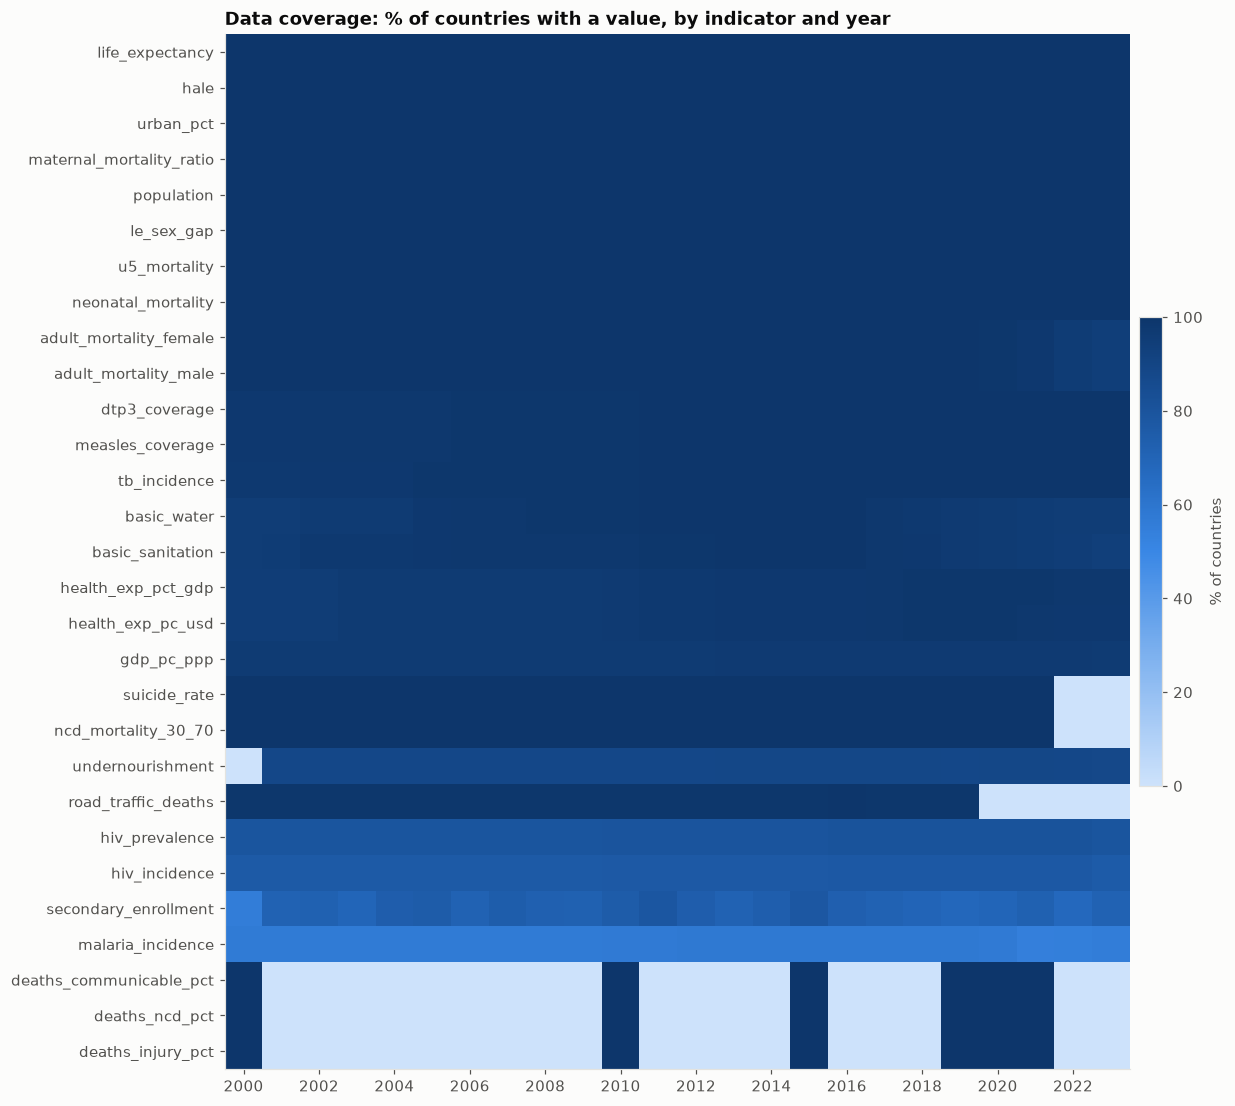

In [3]:
# Share of countries with a value, by indicator and year. Gaps here limit what models can use later.
indicators = [c for c in both.select_dtypes("number").columns
              if c not in ("year", "log_gdp_pc_ppp") and not c.endswith(("_low", "_high"))]
coverage = (both.groupby("year")[indicators].apply(lambda g: g.notna().mean() * 100).T)
coverage = coverage.loc[coverage.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 0.38 * len(indicators) + 1.2))
cmap = LinearSegmentedColormap.from_list("seq", SEQUENTIAL)
im = ax.imshow(coverage.values, aspect="auto", cmap=cmap, vmin=0, vmax=100)
ax.set_yticks(range(len(coverage)), coverage.index)
step = max(1, len(coverage.columns) // 12)
ax.set_xticks(range(0, len(coverage.columns), step), coverage.columns[::step])
ax.grid(False)
ax.set_title("Data coverage: % of countries with a value, by indicator and year")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, label="% of countries")
save(fig, "01_data_coverage")
plt.show()

**What to look for:** indicators with patchy coverage (often schooling, undernourishment and health spending) or that stop a few years before the outcome data. Note them in your README; they decide which variables the models can use and which years can be compared.

## 2. Regional trends

Regional averages are **weighted by population**, matching how WHO reports regional figures. An unweighted average would let a small island count as much as Nigeria or India.

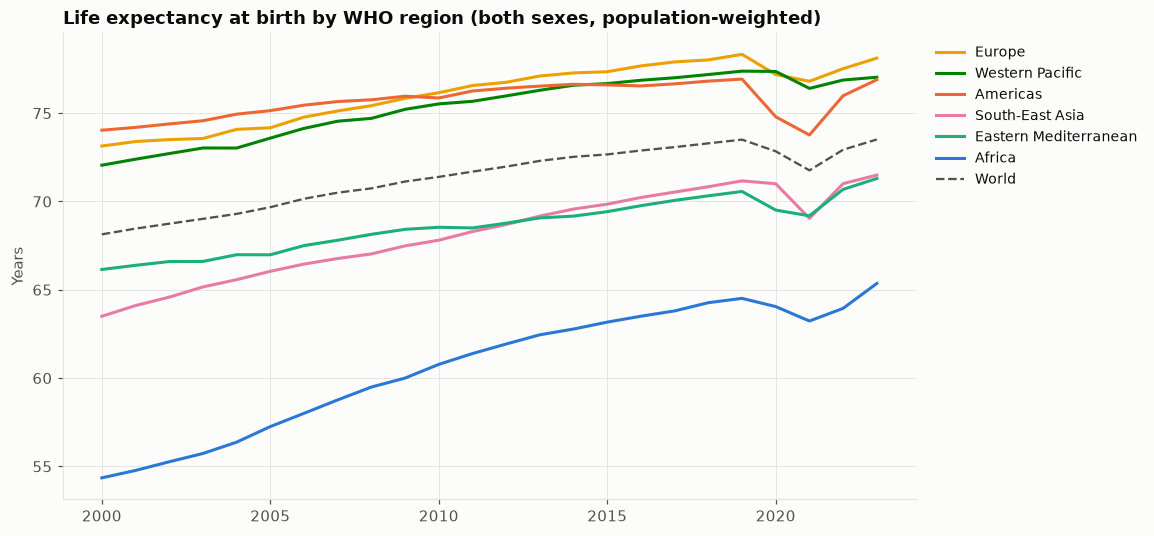

who_region,Africa,Americas,Eastern Mediterranean,Europe,South-East Asia,Western Pacific
year,,,,,,
2000,54.3,74.0,66.1,73.1,63.5,72.1
2023,65.4,76.9,71.3,78.1,71.5,77.0


In [4]:
def weighted_mean(df, value, weight="population"):
    ok = df[value].notna() & df[weight].notna()
    return np.average(df.loc[ok, value], weights=df.loc[ok, weight]) if ok.any() else np.nan

regional = (both.groupby(["who_region", "year"])
                .apply(lambda g: weighted_mean(g, "life_expectancy"), include_groups=False)
                .rename("life_expectancy").reset_index()
                .dropna())
global_avg = both.groupby("year").apply(lambda g: weighted_mean(g, "life_expectancy"), include_groups=False).dropna()

fig, ax = plt.subplots(figsize=(10, 5.5))
# Legend order follows the latest value (top to bottom) so it reads like the chart
order = regional[regional["year"] == regional["year"].max()].sort_values("life_expectancy", ascending=False)["who_region"]
for region in order:
    d = regional[regional["who_region"] == region]
    ax.plot(d["year"], d["life_expectancy"], color=REGION_COLORS.get(region, INK_SECONDARY), label=region)
ax.plot(global_avg.index, global_avg.values, color=INK_SECONDARY, linestyle="--", linewidth=1.5, label="World")
ax.set_title("Life expectancy at birth by WHO region (both sexes, population-weighted)")
ax.set_ylabel("Years")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, "02_regional_trends")
plt.show()

regional.pivot(index="year", columns="who_region", values="life_expectancy").round(1).loc[[FIRST, LATEST]]

**What to look for:** which region gained the most since 2000 (in the real data, Africa's rise is driven largely by HIV treatment, malaria control and falling child mortality), whether the gap between regions is closing, and the dip around 2020-2021.

## 3. The gap between women and men

Women live longer than men almost everywhere. How big the gap is, and whether it's changing, is an equity question in its own right.

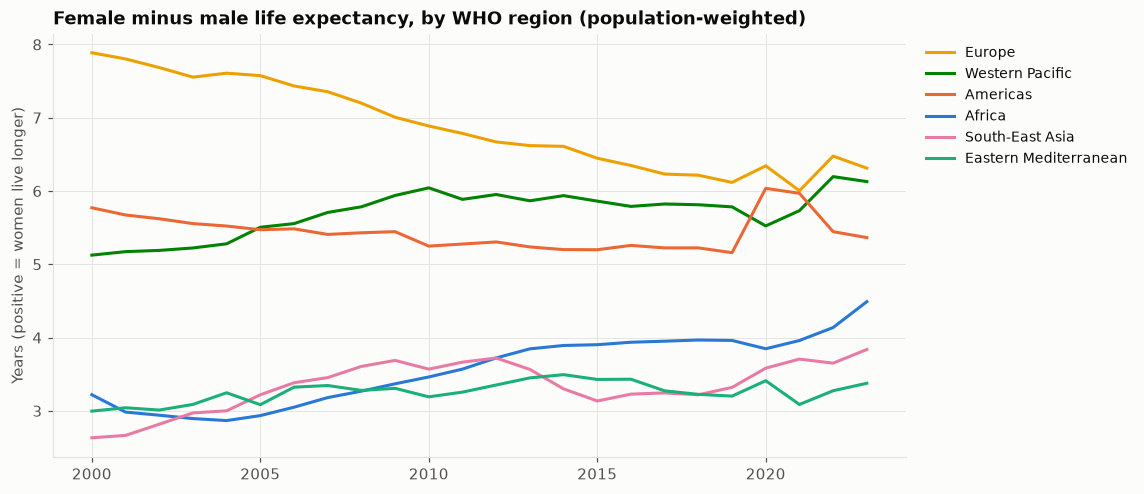

In [5]:
gap = (both.groupby(["who_region", "year"])
           .apply(lambda g: weighted_mean(g, "le_sex_gap"), include_groups=False)
           .rename("gap").reset_index().dropna())

fig, ax = plt.subplots(figsize=(10, 5))
order = gap[gap["year"] == gap["year"].max()].sort_values("gap", ascending=False)["who_region"]
for region in order:
    d = gap[gap["who_region"] == region]
    ax.plot(d["year"], d["gap"], color=REGION_COLORS.get(region, INK_SECONDARY), label=region)
ax.set_title("Female minus male life expectancy, by WHO region (population-weighted)")
ax.set_ylabel("Years (positive = women live longer)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, "03_sex_gap")
plt.show()

## 4. A closer look: one country and one region

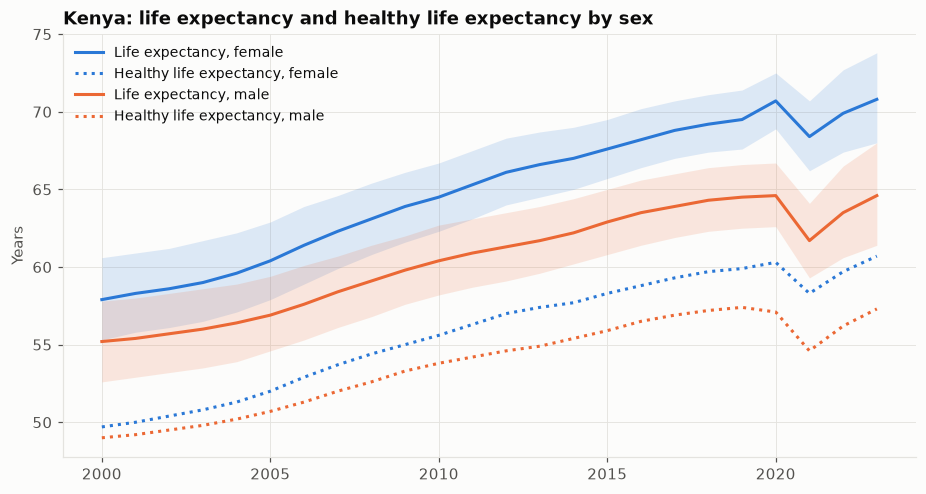

Shaded bands (if shown) are WHO's own uncertainty ranges. Report them; a single line overstates precision.


In [6]:
country = panel[panel["iso3"] == FOCUS_COUNTRY].sort_values("year")
name = country["country"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 5))
for sex in ["female", "male"]:
    d = country[country["sex"] == sex]
    color = SEX_COLORS[sex]
    ax.plot(d["year"], d["life_expectancy"], color=color, label=f"Life expectancy, {sex}")
    if {"life_expectancy_low", "life_expectancy_high"} <= set(d.columns) and d["life_expectancy_low"].notna().any():
        ax.fill_between(d["year"], d["life_expectancy_low"], d["life_expectancy_high"], color=color, alpha=0.15, linewidth=0)
    ax.plot(d["year"], d["hale"], color=color, linestyle=":", label=f"Healthy life expectancy, {sex}")
ax.set_title(f"{name}: life expectancy and healthy life expectancy by sex")
ax.set_ylabel("Years")
ax.legend(fontsize=9, loc="upper left")
save(fig, f"04_{FOCUS_COUNTRY}_profile")
plt.show()

print("Shaded bands (if shown) are WHO's own uncertainty ranges. Report them; a single line overstates precision.")

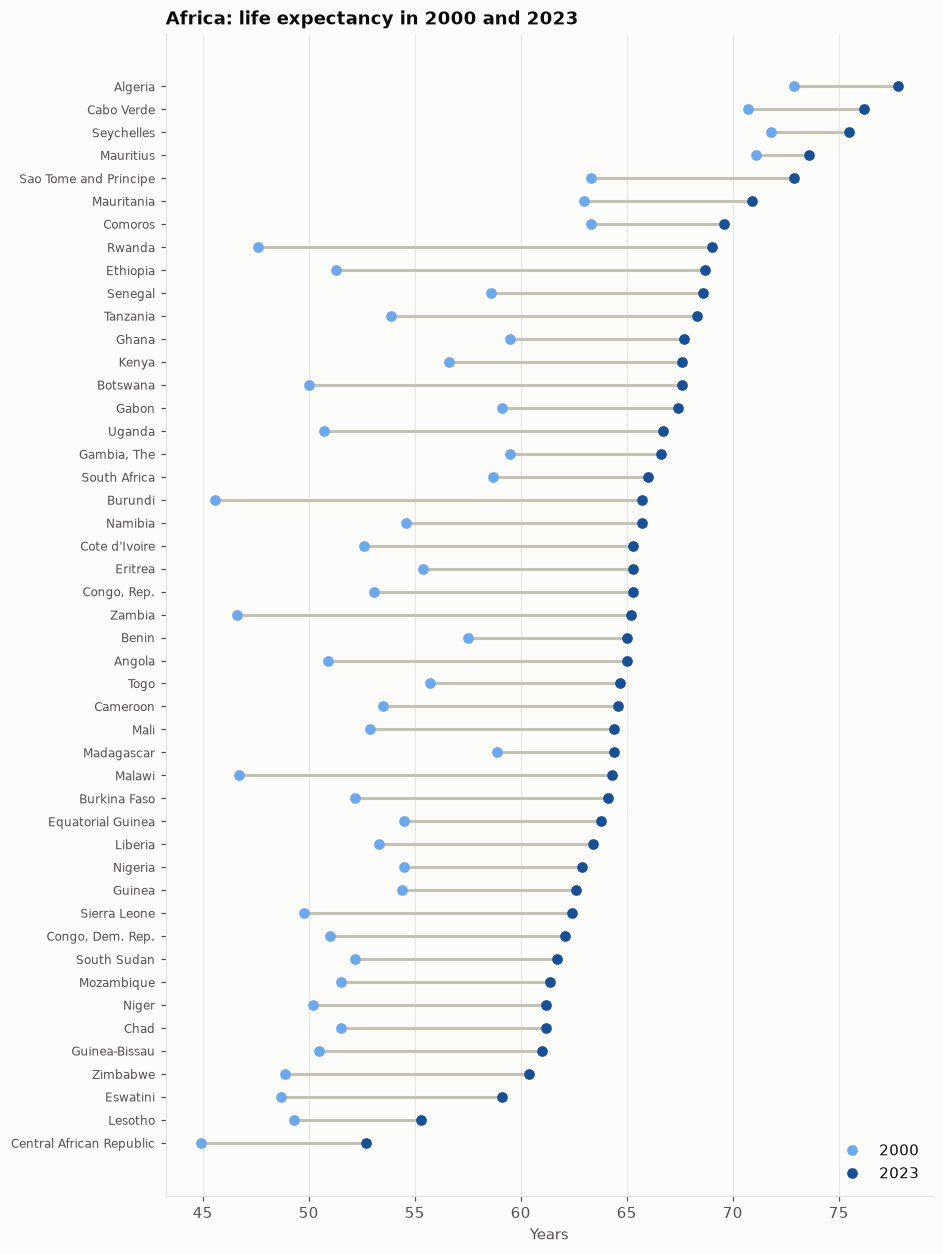

Largest gains:
country
Rwanda      21.4
Burundi     20.1
Zambia      18.6
Malawi      17.6
Botswana    17.6

Smallest gains:
country
Mauritius     2.5
Seychelles    3.7
Algeria       4.9
Cabo Verde    5.5
Madagascar    5.5


In [7]:
# Change since the first year, for every country in the focus region
region = both[both["who_region"] == FOCUS_REGION]
change = (region[region["year"].isin([FIRST, LATEST])]
          .pivot_table(index="country", columns="year", values="life_expectancy")
          .dropna())
change["gain"] = change[LATEST] - change[FIRST]
change = change.sort_values(LATEST)

fig, ax = plt.subplots(figsize=(9, 0.26 * len(change) + 1.5))
y = np.arange(len(change))
ax.hlines(y, change[FIRST], change[LATEST], color="#c3c2b7", linewidth=2)
ax.plot(change[FIRST], y, "o", color=SEQUENTIAL[2], markersize=6, label=str(FIRST))
ax.plot(change[LATEST], y, "o", color=SEQUENTIAL[5], markersize=6, label=str(LATEST))
ax.set_yticks(y, change.index, fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_title(f"{FOCUS_REGION}: life expectancy in {FIRST} and {LATEST}")
ax.set_xlabel("Years")
ax.legend(loc="lower right")
save(fig, "05_region_change")
plt.show()

print("Largest gains:"); print(change["gain"].sort_values(ascending=False).head(5).round(1).to_string())
print("\nSmallest gains:"); print(change["gain"].sort_values().head(5).round(1).to_string())

## 5. The COVID-19 shock

Change in life expectancy from 2019 to the latest year, by region. This matters for forecasting: a model trained on smooth pre-2020 trends would not have predicted this drop, and any forecast needs to say how it treats shocks like this.

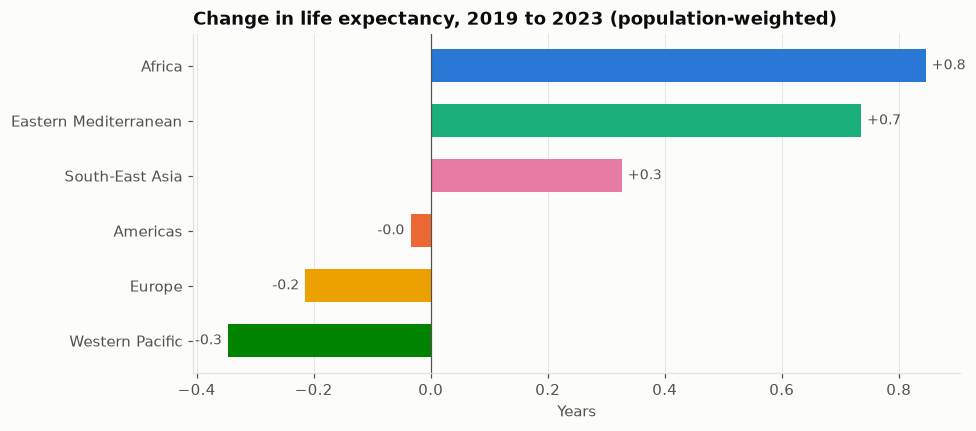

In [8]:
if 2019 in set(regional["year"]) and LATEST > 2019:
    pre = regional[regional["year"] == 2019].set_index("who_region")["life_expectancy"]
    post = regional[regional["year"] == LATEST].set_index("who_region")["life_expectancy"]
    shock = (post - pre).dropna().sort_values()

    fig, ax = plt.subplots(figsize=(9, 4))
    colors = [REGION_COLORS.get(r, INK_SECONDARY) for r in shock.index]
    ax.barh(shock.index, shock.values, color=colors, height=0.6)
    for i, v in enumerate(shock.values):
        ax.annotate(f"{v:+.1f}", xy=(v, i), xytext=(-4 if v < 0 else 4, 0), textcoords="offset points",
                    ha="right" if v < 0 else "left", va="center", fontsize=9, color=INK_SECONDARY)
    ax.axvline(0, color=INK_SECONDARY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Change in life expectancy, 2019 to {LATEST} (population-weighted)")
    ax.set_xlabel("Years")
    save(fig, "06_covid_shock")
    plt.show()
else:
    print("Data doesn't span 2019 and a later year, so the COVID comparison is skipped.")

## 6. Living longer, but how many years in good health?

HALE counts only the years lived in full health. The difference between life expectancy and HALE is the average number of years lived with illness or disability, a key measure for health systems.

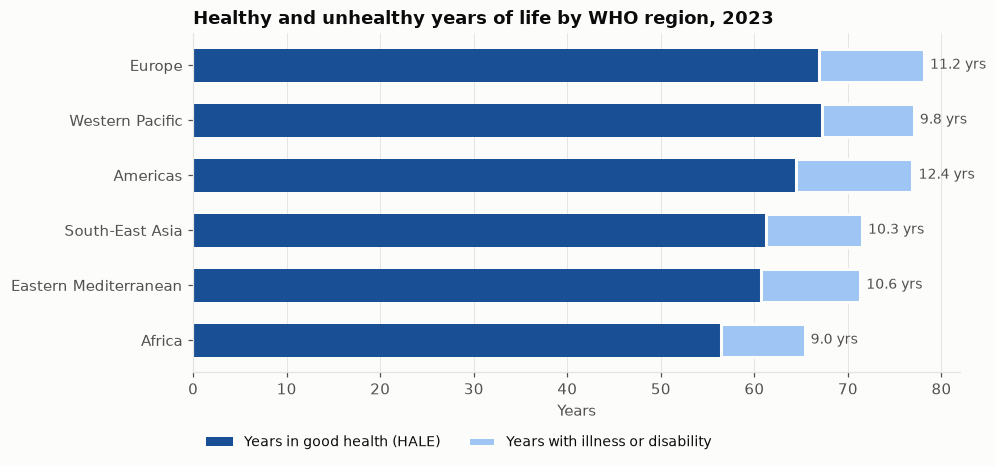

In [9]:
latest_both = both[both["year"] == LATEST].copy()
latest_both["years_ill_health"] = latest_both["life_expectancy"] - latest_both["hale"]
ill = (latest_both.groupby("who_region")
       .apply(lambda g: pd.Series({"Life expectancy": weighted_mean(g, "life_expectancy"),
                                   "HALE": weighted_mean(g, "hale")}), include_groups=False)
       .dropna().sort_values("Life expectancy"))

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(ill))
ax.barh(y, ill["HALE"], color=SEQUENTIAL[5], height=0.6, label="Years in good health (HALE)")
ax.barh(y, ill["Life expectancy"] - ill["HALE"], left=ill["HALE"], color=SEQUENTIAL[1], height=0.6,
        label="Years with illness or disability", edgecolor=SURFACE, linewidth=2)
for i, (le_, hale_) in enumerate(zip(ill["Life expectancy"], ill["HALE"])):
    ax.annotate(f"{le_ - hale_:.1f} yrs", xy=(le_, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK_SECONDARY)
ax.set_yticks(y, ill.index)
ax.grid(axis="y", visible=False)
ax.set_title(f"Healthy and unhealthy years of life by WHO region, {LATEST}")
ax.set_xlabel("Years")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=2, fontsize=9)
save(fig, "07_hale_gap")
plt.show()

## 7. How life expectancy relates to income and other factors

The classic pattern is the **Preston curve**: life expectancy rises steeply with income in poorer countries, then levels off. Income is plotted on a log scale.

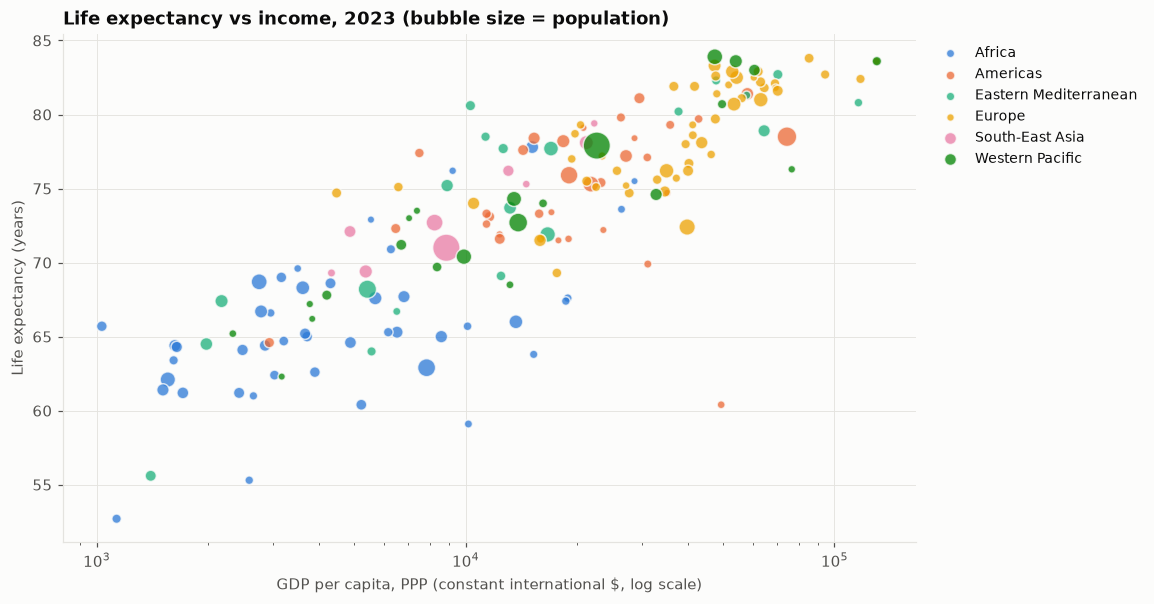

In [10]:
# Use the latest year that has both GDP and life expectancy for most countries
counts = both.dropna(subset=["gdp_pc_ppp", "life_expectancy"]).groupby("year").size()
gdp_year = int(counts[counts >= 0.9 * counts.max()].index.max())
snap = both[(both["year"] == gdp_year)].dropna(subset=["gdp_pc_ppp", "life_expectancy"])

fig, ax = plt.subplots(figsize=(10, 6))
for region, color in REGION_COLORS.items():
    d = snap[snap["who_region"] == region]
    size = 20 + 300 * np.sqrt(d["population"].fillna(d["population"].median()) / snap["population"].max())
    ax.scatter(d["gdp_pc_ppp"], d["life_expectancy"], s=size, color=color, alpha=0.75,
               edgecolor=SURFACE, linewidth=1, label=region)
ax.set_xscale("log")
ax.set_title(f"Life expectancy vs income, {gdp_year} (bubble size = population)")
ax.set_xlabel("GDP per capita, PPP (constant international $, log scale)")
ax.set_ylabel("Life expectancy (years)")
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1), markerscale=0.6)
save(fig, "08_preston_curve")
plt.show()

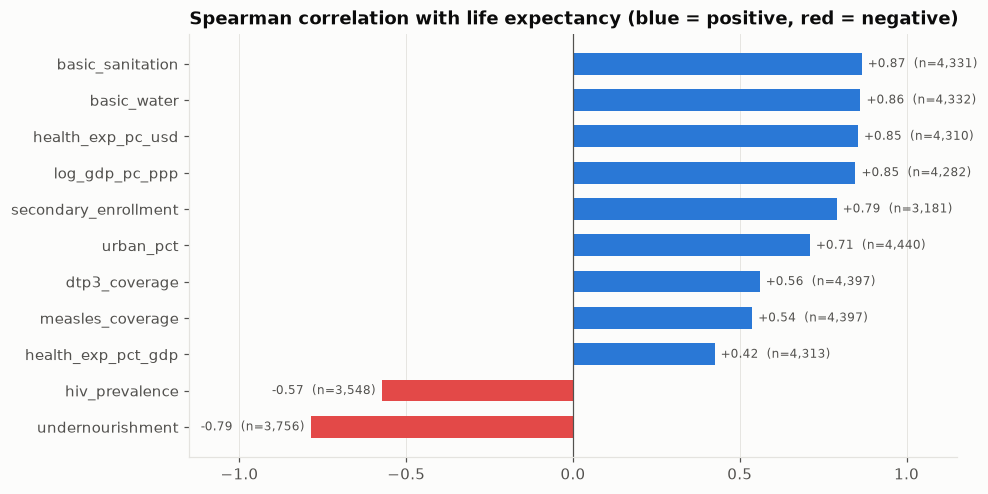

In [11]:
# Rank correlation of each factor with life expectancy (all countries and years pooled)
factors = ["log_gdp_pc_ppp", "health_exp_pct_gdp", "health_exp_pc_usd", "dtp3_coverage", "measles_coverage",
           "hiv_prevalence", "secondary_enrollment", "basic_water", "basic_sanitation", "undernourishment", "urban_pct"]
factors = [f for f in factors if f in both]
corr = both[factors + ["life_expectancy"]].corr(method="spearman")["life_expectancy"].drop("life_expectancy").sort_values()
n_obs = both[factors].notna().sum()

fig, ax = plt.subplots(figsize=(9, 5))
colors = [PALETTE[7] if v < 0 else PALETTE[0] for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, height=0.6)
for i, (f, v) in enumerate(corr.items()):
    ax.annotate(f"{v:+.2f}  (n={n_obs[f]:,})", xy=(v, i), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontsize=8, color=INK_SECONDARY)
ax.axvline(0, color=INK_SECONDARY, linewidth=0.8)
ax.set_xlim(-1.15, 1.15)
ax.grid(axis="y", visible=False)
ax.set_title("Spearman correlation with life expectancy (blue = positive, red = negative)")
save(fig, "09_correlations")
plt.show()

**Be careful with this chart.** These are associations, not causes. Most of these factors rise together with income, so they are strongly correlated with each other. The modelling notebook will separate their effects more carefully (and even then, observational data can't prove causation). Say this plainly in your write-up; it's exactly the kind of judgment public health employers look for.

## Key takeaways (fill these in from your real results)

- **Trends:** ...
- **Inequality between regions:** ...
- **Sex gap:** ...
- **COVID-19:** ...
- **Healthy years:** ...
- **Data limitations:** ...

## Next steps

1. `02_baseline_forecasts.ipynb`: simple baselines (last value, linear trend) and per-country time series models, evaluated by holding out the most recent years.
2. `03_hierarchical_forecast.ipynb`: a Bayesian hierarchical model that lets countries borrow strength from their region, with prediction intervals.
3. `04_drivers.ipynb`: interpretable models of what is associated with life expectancy, with SHAP explanations.
4. A short policy brief and a Streamlit dashboard.